# Model 2 - Random Forest (Member 2)

A Random Forest builds many decision trees on random parts of the data and averages their votes. It captures non-linear patterns and does not need scaling.

## 1. Load the final tables

The tables come from Section 11 of the main notebook (`ML_code.ipynb`): time-based split (train = 2008/09-2013/14, test = 2014/15-2015/16), engineered features, no leakage columns.

In [ ]:
import os
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Define path to your project folder
project_path = '/content/drive/MyDrive/Y3S1/Assignment/Models/'

# Change the current working directory to the project folder
if os.path.exists(project_path):
    os.chdir(project_path)
    print(f"Successfully changed working directory to: {os.getcwd()}")
else:
    print(f"Error: Path '{project_path}' does not exist. Please double-check your Google Drive folder structure.")

Mounted at /content/drive
Successfully changed working directory to: /content/drive/MyDrive/Y3S1/Assignment/Models


In [ ]:
import pandas as pd, numpy as np, json, warnings
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import (accuracy_score, f1_score, log_loss, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
warnings.filterwarnings("ignore")

# Final tables produced by the feature-engineering notebook (upload the 5 files to the same folder)
train      = pd.read_csv("train_final.csv", parse_dates=["date"]).sort_values(["date", "match_api_id"])
test       = pd.read_csv("test_final.csv", parse_dates=["date"])
train_odds = pd.read_csv("train_final_odds.csv", parse_dates=["date"]).sort_values(["date", "match_api_id"])
test_odds  = pd.read_csv("test_final_odds.csv", parse_dates=["date"])
feats = json.load(open("final_feature_sets.json"))

# Two experiments: our own features only, and our features + bookmaker odds
experiments = {
    "No odds":   (train,      test,      feats["features_no_odds"]),
    "With odds": (train_odds, test_odds, feats["features_with_odds"]),
}
class_names = ["Away win", "Draw", "Home win"]      # target: 0 = A, 1 = D, 2 = H
for name, (tr, te, cols) in experiments.items():
    print(f"{name:10s} train {tr.shape[0]:6d} | test {te.shape[0]:5d} | features {len(cols)}")

No odds    train  19328 | test  6651 | features 16
With odds  train  16783 | test  5809 | features 18


## 2. Evaluation helper

The test set is used **only once**, after tuning. Metrics: accuracy, macro F1 (main metric), weighted F1, log loss and draw recall.

In [ ]:
def evaluate(model, X, y, label, exp):
    """Test-set metrics. Macro F1 is the main metric because draws are the hardest class."""
    pred = model.predict(X)
    proba = model.predict_proba(X) if hasattr(model, "predict_proba") else None
    report = classification_report(y, pred, output_dict=True, zero_division=0)
    return {"model": label, "features": exp,
            "accuracy": round(accuracy_score(y, pred), 4),
            "macro_F1": round(f1_score(y, pred, average="macro"), 4),
            "weighted_F1": round(f1_score(y, pred, average="weighted"), 4),
            "log_loss": round(log_loss(y, proba), 4) if proba is not None else np.nan,
            "draw_recall": round(report["1"]["recall"], 4)}

def show_confusion(model, X, y, title):
    ConfusionMatrixDisplay.from_predictions(y, model.predict(X), display_labels=class_names, cmap="Blues", colorbar=False)
    plt.title(title)
    plt.show()

## 3. Tune and train the Random Forest

`max_depth` and `min_samples_leaf` limit how detailed each tree can be, which controls overfitting. `class_weight='balanced'` is used for the same reason as before.

Hyper-parameters are tuned with `GridSearchCV` and `TimeSeriesSplit` **inside the training data only** (each fold validates on a later period than it trains on), scored by macro F1.

No odds | best parameters: {'max_depth': 6, 'min_samples_leaf': 30} | CV macro F1: 0.4302


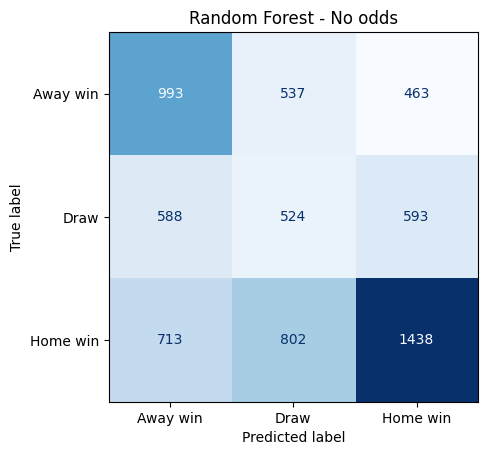

With odds | best parameters: {'max_depth': 6, 'min_samples_leaf': 30} | CV macro F1: 0.4659


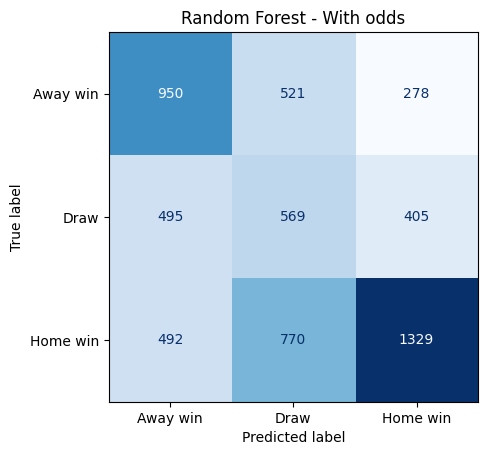

In [ ]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1)
grid = {'max_depth': [4, 6, 10], 'min_samples_leaf': [10, 30, 60]}

results, best_models = [], {}
cv = TimeSeriesSplit(n_splits=3)

for exp, (tr, te, cols) in experiments.items():
    X_tr, y_tr, X_te, y_te = tr[cols], tr["target"], te[cols], te["target"]
    search = GridSearchCV(model, grid, cv=cv, scoring="f1_macro", n_jobs=-1)
    search.fit(X_tr, y_tr)
    best_models[exp] = search.best_estimator_
    print(exp, "| best parameters:", search.best_params_, "| CV macro F1:", round(search.best_score_, 4))
    results.append(evaluate(search.best_estimator_, X_te, y_te, "Random Forest", exp))
    show_confusion(search.best_estimator_, X_te, y_te, f"Random Forest - {exp}")

## 4. Results on the test seasons (2014/15 - 2015/16)

In [ ]:
results_table = pd.DataFrame(results)
results_table.to_csv("results_02_random_forest.csv", index=False)
results_table

,model,features,accuracy,macro_F1,weighted_F1,log_loss,draw_recall
0,Random Forest,No odds,0.4443,0.4283,0.4485,1.0459,0.3073
1,Random Forest,With odds,0.4903,0.4783,0.4992,1.0017,0.3873


## 5. Interpretation of the model

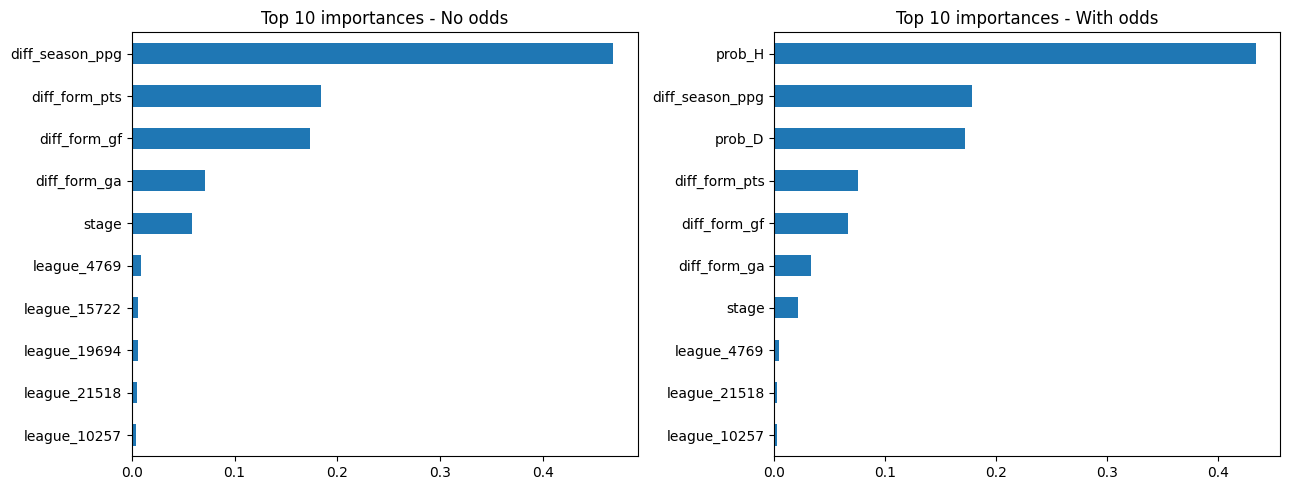

In [ ]:
# Feature importance (how much each feature reduces impurity)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (exp, (tr, te, cols)) in zip(axes, experiments.items()):
    imp = pd.Series(best_models[exp].feature_importances_, index=cols).sort_values().tail(10)
    imp.plot(kind="barh", ax=ax, title=f"Top 10 importances - {exp}")
plt.tight_layout()
plt.show()

In [ ]:
from google.colab import files

files.download('results_02_random_forest.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>